# Top 10 五日收益率榜单组合回测

本 Notebook 使用 WT8 CSV，对 Long & Hold、小时 SAR 多头、小时 MACD 多头三种策略分别回测。每个品种最多持有一手，组合最多同时持有十个品种。每个小时观察时点，使用该品种在此时点之前五个有数据交易日的 WT8 权益收益率排名；进入 Top 10 后开仓，跌出 Top 10 后平仓。

## 计算口径

- 五日排名收益率：`观察时点策略权益 ÷ 五个交易日之前的策略权益 - 1`。两端取各品种在对应交易日期、同一小时或此前最近一条有效记录；不足五个历史交易日的品种不参与排名。
- 同一时点主力换月的重复行按最后一行作为该时点快照。回测信号在观察时点产生，委托在该品种下一条可交易记录成交。
- 一手盈亏为`价格变化 × 合约乘数`。杠杆通过保证金占用体现，不会再乘一次。
- 手续费按 WT8 导出数据与配置计算；滑点和主连换月价差未建模。

该回测用于研究五日收益率榜单的组合表现，不代表实际成交结果。


In [1]:
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import datetime, timedelta
from html import escape
from itertools import groupby
from heapq import merge
from pathlib import Path
from statistics import median
from typing import NamedTuple
import csv
import math
import re
import statistics

# Notebook 可从项目根目录打开，也可从 notebooks/ 目录打开。
BASE_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("找不到项目 data/ 目录；请从 Futures_Ranking 或其 notebooks/ 目录运行。")

STRATEGY_DIRS = {
    "long_hold": "小时Buy_And_Hold",
    "sar_long": "小时SAR多头",
    "macd_long": "小时MACD多头",
}
STRATEGY_NAMES = {
    "long_hold": "Long & Hold（五日收益率榜）",
    "sar_long": "小时 SAR 多头",
    "macd_long": "小时 MACD 多头",
}

INITIAL_CAPITAL = 500_000.0
TOP_K = 10
LOOKBACK_TRADING_DAYS = 5
START_AT = "2024-01-02 09:30:00"
END_AT = None  # None 表示取三套数据共同覆盖到的最后时点
ONE_WAY_FEE_RATE = 0.0  # 单边手续费率；例如 0.0001 表示名义成交额的 1 bp

print("项目目录：", BASE_DIR)
print("排名口径：观察时点前", LOOKBACK_TRADING_DAYS, "个有数据交易日的权益收益率")
print("回测区间：", START_AT, "至数据共同末时点")
print("初始资金：", f"{INITIAL_CAPITAL:,.0f}", "元；每品种 1 手；组合最多", TOP_K, "个品种")

项目目录： d:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking
排名口径：观察时点前 5 个有数据交易日的权益收益率
回测区间： 2024-01-02 09:30:00 至数据共同末时点
初始资金： 500,000 元；每品种 1 手；组合最多 10 个品种


## 1. 读取和检查 WT8 明细

以下按 CSV 的固定列读取：时间、合约、信号、价格、平仓/开仓手数、成交额、手续费、可用资金、权益。读取时同时根据 BK/SP 还原 WT8 每个单品种策略自己的持仓状态，用于估算保证金率。


In [2]:
class Bar(NamedTuple):
    timestamp: datetime
    contract: str
    signal: str
    price: float | None
    turnover: float | None
    trade_qty: float | None
    equity: float
    available: float | None
    position: int
    fee: float | None


def parse_number(value):
    text = str(value or "").replace("\ufeff", "").strip().replace(",", "")
    if not text or text in {"---", "--", "-"}:
        return None
    try:
        return float(text)
    except ValueError:
        return None


def parse_timestamp(value):
    text = str(value or "").replace("\ufeff", "").strip()
    for fmt in ("%Y/%m/%d %H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y/%m/%d %H:%M", "%Y-%m-%d %H:%M"):
        try:
            return datetime.strptime(text, fmt)
        except ValueError:
            pass
    return None


def instrument_name(path):
    name = re.sub(r"_小时.*?_信号明细$", "", path.stem)
    name = re.sub(r"_信号明细$", "", name)
    return re.sub(r"\s+", "", name)


def read_bars(path):
    raw_rows = None
    last_error = None
    for encoding in ("gb18030", "gbk", "utf-8-sig"):
        try:
            with path.open("r", encoding=encoding, errors="strict", newline="") as handle:
                reader = csv.reader(handle)
                next(reader, None)
                raw_rows = list(reader)
            break
        except UnicodeDecodeError as exc:
            last_error = exc
    if raw_rows is None:
        raise UnicodeError(f"无法解码 {path.name}: {last_error}")

    bars = []
    position = 0
    for raw in raw_rows:
        if len(raw) < 15:
            continue
        timestamp = parse_timestamp(raw[1])
        equity = parse_number(raw[14])
        if timestamp is None or equity is None:
            continue  # 汇总行或无效行
        signal = str(raw[3] or "").strip()
        if signal == "BK":
            position = 1
            trade_qty = parse_number(raw[9])
        elif signal in {"SP", "SK", "BP"}:
            trade_qty = parse_number(raw[8])
            if signal == "SP":
                position = 0
            else:
                position = 0
        else:
            trade_qty = None
        bars.append(Bar(
            timestamp=timestamp,
            contract=str(raw[2] or "").strip(),
            signal=signal,
            price=parse_number(raw[7]),
            turnover=parse_number(raw[10]),
            trade_qty=trade_qty,
            equity=equity,
            available=parse_number(raw[13]),
            position=position,
            fee=parse_number(raw[11]),
        ))
    bars.sort(key=lambda bar: bar.timestamp)
    return bars


def format_dt(value):
    return value.strftime("%Y-%m-%d %H:%M:%S") if value else ""


def load_strategy_rows(strategy_id):
    directory = BASE_DIR / "data" / STRATEGY_DIRS[strategy_id]
    result = {}
    for path in sorted(directory.glob("*.csv")):
        name = instrument_name(path)
        bars = read_bars(path)
        if bars:
            result[name] = bars
    return result


print("明细读取函数已准备好。")

明细读取函数已准备好。


## 2. 从 WT8 交易和资金字段估算合约乘数、保证金率

乘数用三套 CSV 的 BK/SP 实际成交金额交叉核对。保证金率不是从网上套一个统一值，而是从每个品种持仓期间的 `权益 - 可用资金` 反推；同一时点若不同策略都有持仓，取这些观察的中位数。回测时只取不晚于当前时点的最近比率，不用未来保证金记录。


In [3]:
MULTIPLIER_SAMPLES = defaultdict(list)
RAW_MARGIN_SAMPLES = defaultdict(list)
DATA_AUDIT = {}
INSTRUMENTS_BY_STRATEGY = {}
DATA_FEES = Counter()

for strategy_id, folder in STRATEGY_DIRS.items():
    paths = sorted((BASE_DIR / "data" / folder).glob("*.csv"))
    row_count = 0
    signals = Counter()
    first_time = None
    last_time = None
    populated = set()
    for path in paths:
        name = instrument_name(path)
        bars = read_bars(path)
        if bars:
            populated.add(name)
        for bar in bars:
            row_count += 1
            first_time = bar.timestamp if first_time is None else min(first_time, bar.timestamp)
            last_time = bar.timestamp if last_time is None else max(last_time, bar.timestamp)
            if bar.signal:
                signals[bar.signal] += 1
            if bar.fee is not None:
                DATA_FEES[strategy_id] += bar.fee
            if bar.signal in {"BK", "SP"} and bar.price and bar.turnover and bar.trade_qty:
                MULTIPLIER_SAMPLES[name].append(bar.turnover / (bar.price * bar.trade_qty))
            if bar.position and bar.price and bar.equity is not None and bar.available is not None:
                margin_amount = bar.equity - bar.available
                if margin_amount > 0:
                    RAW_MARGIN_SAMPLES[name].append((bar.timestamp, margin_amount, bar.price))
    INSTRUMENTS_BY_STRATEGY[strategy_id] = populated
    DATA_AUDIT[strategy_id] = {
        "strategy": STRATEGY_NAMES[strategy_id],
        "files": len(paths),
        "with_rows": len(populated),
        "rows": row_count,
        "first": first_time,
        "last": last_time,
        "BK": signals["BK"],
        "SP": signals["SP"],
    }


CONTRACT_MULTIPLIER = {}
MULTIPLIER_DISPERSION = {}
for name, samples in MULTIPLIER_SAMPLES.items():
    center = median(samples)
    nearest_integer = round(center)
    multiplier = float(nearest_integer) if nearest_integer > 0 and abs(center - nearest_integer) <= max(0.01, center * 0.005) else center
    CONTRACT_MULTIPLIER[name] = multiplier
    MULTIPLIER_DISPERSION[name] = max(abs(value - multiplier) / multiplier for value in samples)


MARGIN_HISTORY = {}
MARGIN_STATS = {}
for name, samples in RAW_MARGIN_SAMPLES.items():
    multiplier = CONTRACT_MULTIPLIER.get(name)
    if not multiplier:
        continue
    dated_rates = []
    for timestamp, margin_amount, price in samples:
        notional = price * multiplier
        rate = margin_amount / notional if notional else None
        if rate is not None and 0.001 <= rate <= 0.50:
            dated_rates.append((timestamp, rate))
    dated_rates.sort(key=lambda item: item[0])
    timeline = []
    for timestamp, grouped in groupby(dated_rates, key=lambda item: item[0]):
        same_time_rates = [item[1] for item in grouped]
        timeline.append((timestamp, median(same_time_rates)))
    if timeline:
        MARGIN_HISTORY[name] = timeline
        all_rates = [item[1] for item in timeline]
        MARGIN_STATS[name] = {
            "samples": len(dated_rates),
            "observations": len(timeline),
            "median": median(all_rates),
            "min": min(all_rates),
            "max": max(all_rates),
        }
MARGIN_TIMES = {name: [item[0] for item in history] for name, history in MARGIN_HISTORY.items()}


COMMON_UNIVERSE = set.intersection(*(set(names) for names in INSTRUMENTS_BY_STRATEGY.values()))
COMMON_UNIVERSE &= set(CONTRACT_MULTIPLIER)
COMMON_UNIVERSE &= set(MARGIN_HISTORY)
ALL_SEEN_INSTRUMENTS = set.union(*(set(names) for names in INSTRUMENTS_BY_STRATEGY.values()))
EXCLUDED_INSTRUMENTS = sorted(ALL_SEEN_INSTRUMENTS - COMMON_UNIVERSE)
if not COMMON_UNIVERSE:
    raise RuntimeError("没有同时具备价格、合约乘数和保证金率的可回测品种。")

START_DT = parse_timestamp(START_AT)
latest_per_strategy = [DATA_AUDIT[key]["last"] for key in STRATEGY_DIRS]
COMMON_LAST_DT = min(latest_per_strategy)
END_DT = parse_timestamp(END_AT) if END_AT else COMMON_LAST_DT
if START_DT is None or END_DT is None or START_DT >= END_DT:
    raise ValueError("请设置有效回测区间，且起始时点必须早于结束时点。")

def margin_rate_at(name, timestamp):
    history = MARGIN_HISTORY.get(name, [])
    times = MARGIN_TIMES.get(name, [])
    idx = bisect_right(times, timestamp) - 1
    return history[idx][1] if idx >= 0 else None


from bisect import bisect_right

def margin_table_rows():
    rows = []
    for name in sorted(COMMON_UNIVERSE):
        stats = MARGIN_STATS[name]
        start_rate = margin_rate_at(name, START_DT)
        rows.append({
            "品种": name,
            "合约乘数": CONTRACT_MULTIPLIER[name],
            "乘数反推成交笔数": len(MULTIPLIER_SAMPLES[name]),
            "乘数最大偏差": MULTIPLIER_DISPERSION[name],
            "起始保证金率": start_rate,
            "起始隐含杠杆": 1 / start_rate if start_rate else None,
            "期间保证金率中位数": stats["median"],
            "期间保证金率最低": stats["min"],
            "期间保证金率最高": stats["max"],
            "WT8保证金观察数": stats["samples"],
        })
    return rows


def show_html(html):
    try:
        from IPython.display import HTML, display
        display(HTML(html))
    except ImportError:
        print("当前 Python 环境没有 IPython，Notebook 在 Jupyter 中会显示 HTML 图表和表格。")


def show_table(rows, columns, percent_columns=(), number_columns=()):
    head = "".join(f"<th>{escape(col)}</th>" for col in columns)
    body = []
    for row in rows:
        cells = []
        for col in columns:
            value = row.get(col)
            if value is None:
                rendered = "—"
            elif col in percent_columns:
                rendered = f"{value * 100:,.2f}%"
            elif col in number_columns:
                rendered = f"{value:,.2f}"
            elif isinstance(value, datetime):
                rendered = format_dt(value)
            elif isinstance(value, float):
                rendered = f"{value:,.4f}"
            else:
                rendered = str(value)
            cells.append(f"<td>{escape(rendered)}</td>")
        body.append("<tr>" + "".join(cells) + "</tr>")
    html = "<table style='border-collapse:collapse;font-size:13px'>"
    html += "<thead><tr>" + head + "</tr></thead><tbody>" + "".join(body) + "</tbody></table>"
    show_html(html)


audit_rows = []
for key in STRATEGY_DIRS:
    audit = DATA_AUDIT[key]
    audit_rows.append({
        "策略": audit["strategy"],
        "CSV文件": audit["files"],
        "有行情的品种": audit["with_rows"],
        "有效行数": audit["rows"],
        "BK开仓信号": audit["BK"],
        "SP平仓信号": audit["SP"],
        "开始": audit["first"],
        "结束": audit["last"],
        "CSV手续费合计": DATA_FEES[key],
    })
show_table(audit_rows, ["策略", "CSV文件", "有行情的品种", "有效行数", "BK开仓信号", "SP平仓信号", "开始", "结束", "CSV手续费合计"])
print(f"三套数据共同有完整参数的品种：{len(COMMON_UNIVERSE)} 个。未纳入：{', '.join(EXCLUDED_INSTRUMENTS) or '无'}（成交记录不足，无法由本地 WT8 明细验证一手乘数和保证金率）。")
print(f"有效区间：{format_dt(START_DT)} 至 {format_dt(END_DT)}；每个品种的榜单评分只使用不晚于当前时点的最近 WT8 记录。")
print("所有 CSV 的手续费字段合计为 0；基准回测也按 0 计费。")


策略,CSV文件,有行情的品种,有效行数,BK开仓信号,SP平仓信号,开始,结束,CSV手续费合计
Long & Hold（五日收益率榜）,83,83,297211,1398,0,2024-01-02 02:00:00,2026-10-09 15:00:00,0.0000
小时 SAR 多头,83,83,296552,18291,17578,2024-01-02 02:00:00,2026-10-09 15:00:00,0.0000
小时 MACD 多头,83,83,296596,12220,11468,2024-01-02 02:00:00,2026-10-09 15:00:00,0.0000


三套数据共同有完整参数的品种：82 个。未纳入：强麦主连（成交记录不足，无法由本地 WT8 明细验证一手乘数和保证金率）。
有效区间：2024-01-02 09:30:00 至 2026-10-09 15:00:00；每个品种的榜单评分只使用不晚于当前时点的最近 WT8 记录。
所有 CSV 的手续费字段合计为 0；基准回测也按 0 计费。


## 3. 每个品种的一手合约参数

表内起始保证金率是回测起点之前/当时已经由 WT8 持仓记录观察到的比率；回测持仓保证金随着 WT8 后续已发生的保证金率更新。`保证金率期间中位数/最高/最低` 用来检视各品种、各时段的差异，不参与未来时点的参数回填。


In [4]:
margin_rows = margin_table_rows()
show_table(
    margin_rows,
    ["品种", "合约乘数", "乘数反推成交笔数", "乘数最大偏差", "起始保证金率", "起始隐含杠杆", "期间保证金率中位数", "期间保证金率最低", "期间保证金率最高", "WT8保证金观察数"],
    percent_columns={"乘数最大偏差", "起始保证金率", "期间保证金率中位数", "期间保证金率最低", "期间保证金率最高"},
    number_columns={"合约乘数", "乘数反推成交笔数", "起始隐含杠杆", "WT8保证金观察数"},
)
print("说明：隐含杠杆 = 1 ÷ 保证金率；例如 10% 保证金率约对应 10 倍名义敞口。实际可用杠杆受资金、风控和交易所/期货公司调整限制。")

品种,合约乘数,乘数反推成交笔数,乘数最大偏差,起始保证金率,起始隐含杠杆,期间保证金率中位数,期间保证金率最低,期间保证金率最高,WT8保证金观察数
1000股指主连,200.00,533.00,0.00%,12.00%,8.33,11.89%,8.44%,14.90%,"5,445.00"
20号胶主连,10.00,869.00,0.00%,9.00%,11.11,8.97%,7.85%,10.82%,"8,121.00"
300股指主连,300.00,566.00,0.00%,12.00%,8.33,11.95%,8.75%,13.69%,"5,445.00"
500股指主连,200.00,565.00,0.00%,12.00%,8.33,11.87%,8.61%,14.18%,"5,409.00"
50股指主连,300.00,588.00,0.00%,12.00%,8.33,11.94%,9.06%,13.32%,"5,428.00"
BR橡胶主连,5.00,869.00,0.00%,12.00%,8.33,11.95%,9.52%,15.04%,"8,109.00"
LU燃油主连,10.00,839.00,0.00%,16.00%,6.25,15.91%,8.91%,18.89%,"8,118.00"
PTA主连,5.00,804.00,0.00%,7.00%,14.29,7.00%,4.72%,8.69%,"8,014.00"
PVC主连,5.00,819.00,0.00%,7.00%,14.28,7.01%,5.49%,8.48%,"7,872.00"
三十年债主连,"10,000.00",648.00,0.00%,3.50%,28.57,3.49%,3.25%,3.68%,"6,977.00"


说明：隐含杠杆 = 1 ÷ 保证金率；例如 10% 保证金率约对应 10 倍名义敞口。实际可用杠杆受资金、风控和交易所/期货公司调整限制。


## 4. 按近五个交易日收益率排名的 Top 10 一手组合

每个 WT8 小时观察时点，按品种自己的五个交易日权益收益率从高到低取 Top 10。五日前基准使用第五个此前有行情的日期、当前小时或之前最近的权益记录；不足五个历史交易日或缺少同日基准记录时，该品种暂不参与排名。进入 Top 10 后，在该品种下一条可交易记录开一手；跌出 Top 10 后，在下一条可交易记录平仓。组合最多持有十个品种，并按逐时可用保证金控制开仓、记录拒单和强平。

所有日期与收益率只使用当前观察时点或此前的数据，不引用未来 WT8 记录。


In [5]:
def portfolio_margin(positions, timestamp):
    total = 0.0
    for name, position in positions.items():
        rate = margin_rate_at(name, timestamp)
        if rate is None:
            rate = position["last_margin_rate"]
        price = position["last_price"]
        if rate is not None and price is not None:
            total += price * CONTRACT_MULTIPLIER[name] * rate
    return total


def run_backtest(strategy_id):
    all_rows = load_strategy_rows(strategy_id)
    bars_by_instrument = {name: rows for name, rows in all_rows.items() if name in COMMON_UNIVERSE}
    instruments = sorted(bars_by_instrument)

    five_day_returns = {}
    latest = {}
    latest_index = {}
    latest_return = {}
    for name, bars in bars_by_instrument.items():
        # Collapse roll duplicates by timestamp, then use the same clock time five data-bearing dates earlier.
        instrument_returns = [None] * len(bars)
        groups = []
        left = 0
        while left < len(bars):
            right = left + 1
            while right < len(bars) and bars[right].timestamp == bars[left].timestamp:
                right += 1
            active = bars[right - 1]
            groups.append((left, right, active.timestamp, active.equity))
            left = right

        groups_by_date = defaultdict(list)
        for group in groups:
            groups_by_date[group[2].date()].append(group)
        trading_dates = sorted(groups_by_date)
        date_indices = {day: index for index, day in enumerate(trading_dates)}
        clock_times = {
            day: [group[2].time() for group in day_groups]
            for day, day_groups in groups_by_date.items()
        }
        for group in groups:
            row_start, row_end, end_time, end_equity = group
            date_index = date_indices[end_time.date()]
            if date_index < LOOKBACK_TRADING_DAYS:
                continue
            start_date = trading_dates[date_index - LOOKBACK_TRADING_DAYS]
            start_groups = groups_by_date[start_date]
            start_index = bisect_right(clock_times[start_date], end_time.time()) - 1
            if start_index < 0:
                continue
            start_equity = start_groups[start_index][3]
            if start_equity <= 0:
                continue
            trailing_return = end_equity / start_equity - 1.0
            for row_index in range(row_start, row_end):
                instrument_returns[row_index] = trailing_return
        five_day_returns[name] = instrument_returns

        times = [bar.timestamp for bar in bars]
        idx = bisect_right(times, START_DT) - 1
        if idx >= 0:
            latest[name] = bars[idx]
            latest_index[name] = idx
            latest_return[name] = instrument_returns[idx]

    streams = []
    def bar_event_stream(bars, instrument, begin_index, stop_index):
        for row_index in range(begin_index, stop_index):
            yield (bars[row_index].timestamp, instrument, row_index)

    for name, bars in bars_by_instrument.items():
        times = [bar.timestamp for bar in bars]
        begin = bisect_right(times, START_DT)
        stop = bisect_right(times, END_DT)
        if begin < stop:
            streams.append(bar_event_stream(bars, name, begin, stop))
    event_stream = merge(*streams)

    positions = {}
    pending = {}
    trades = []
    rejected_entries = []
    position_snapshots = []
    gross_pnl = 0.0
    fees_paid = 0.0
    roll_count = 0
    equity_curve = [{
        "timestamp": START_DT,
        "equity": INITIAL_CAPITAL,
        "gross_pnl": 0.0,
        "fees": 0.0,
        "margin_used": 0.0,
        "available": INITIAL_CAPITAL,
        "positions": 0,
    }]

    def close_at(name, timestamp, price, reason):
        nonlocal fees_paid
        position = positions.pop(name)
        multiplier = CONTRACT_MULTIPLIER[name]
        exit_notional = price * multiplier
        exit_fee = exit_notional * ONE_WAY_FEE_RATE
        fees_paid += exit_fee
        net = position["gross_pnl"] - position["entry_fee"] - exit_fee
        trades.append({
            "strategy": STRATEGY_NAMES[strategy_id],
            "instrument": name,
            "entry_time": position["entry_time"],
            "exit_time": timestamp,
            "entry_contract": position["entry_contract"],
            "exit_contract": position["contract"],
            "entry_price": position["entry_price"],
            "exit_price": price,
            "multiplier": multiplier,
            "entry_notional": position["entry_notional"],
            "entry_margin": position["entry_margin"],
            "gross_pnl": position["gross_pnl"],
            "fees": position["entry_fee"] + exit_fee,
            "net_pnl": net,
            "margin_return": net / position["entry_margin"] if position["entry_margin"] else None,
            "holding_hours": (timestamp - position["entry_time"]).total_seconds() / 3600,
            "rolls": position["rolls"],
            "exit_reason": reason,
        })

    def record_position_snapshot(timestamp, equity, margin_used, ranks):
        portfolio_pnl = equity - INITIAL_CAPITAL
        common = {
            "timestamp": timestamp,
            "position_count": len(positions),
            "margin_used": margin_used,
            "portfolio_pnl": portfolio_pnl,
            "equity": equity,
        }
        if not positions:
            position_snapshots.append({
                **common,
                "instrument": "",
                "contract": "",
                "entry_time": None,
                "entry_price": None,
                "mark_price": None,
                "multiplier": None,
                "floating_pnl": 0.0,
                "floating_return_on_margin": None,
                "rank": None,
                "five_day_return": None,
            })
            return
        ordered = sorted(positions.items(), key=lambda item: (ranks.get(item[0], TOP_K + 1), item[0]))
        for name, position in ordered:
            floating_pnl = position["gross_pnl"] - position["entry_fee"]
            position_snapshots.append({
                **common,
                "instrument": name,
                "contract": position["contract"],
                "entry_time": position["entry_time"],
                "entry_price": position["entry_price"],
                "mark_price": position["last_price"],
                "multiplier": CONTRACT_MULTIPLIER[name],
                "floating_pnl": floating_pnl,
                "floating_return_on_margin": floating_pnl / position["entry_margin"] if position["entry_margin"] else None,
                "rank": ranks.get(name),
                "five_day_return": latest_return.get(name),
            })

    for timestamp, grouped_events in groupby(event_stream, key=lambda item: item[0]):
        rows_now = {}
        for _, name, index in grouped_events:
            bar = bars_by_instrument[name][index]
            rows_now[name] = (index, bar)

            if name in positions and bar.price is not None:
                position = positions[name]
                old_contract = position["contract"]
                if old_contract and bar.contract and old_contract != bar.contract:
                    # 连续主连切换时不将跨月价差计作价格盈亏。
                    position["rolls"] += 1
                    roll_count += 1
                elif position["last_price"] is not None:
                    change_pnl = (bar.price - position["last_price"]) * CONTRACT_MULTIPLIER[name]
                    position["gross_pnl"] += change_pnl
                    gross_pnl += change_pnl
                position["last_price"] = bar.price
                position["contract"] = bar.contract or old_contract
            latest[name] = bar
            latest_index[name] = index
            latest_return[name] = five_day_returns[name][index]

        due = []
        for name, (index, bar) in rows_now.items():
            order = pending.get(name)
            if order and index >= order["due_index"]:
                due.append((name, index, bar, order))

        # 同一时点先平仓释放保证金，再按之前的名次顺序开仓。
        for name, index, bar, order in sorted((item for item in due if item[3]["action"] == "exit"), key=lambda item: item[0]):
            pending.pop(name, None)
            if name in positions and bar.price is not None:
                close_at(name, timestamp, bar.price, "跌出Top 10")

        due_entries = sorted((item for item in due if item[3]["action"] == "enter"), key=lambda item: (item[3]["rank"], item[0]))
        for name, index, bar, order in due_entries:
            pending.pop(name, None)
            if name in positions or bar.price is None:
                continue
            if len(positions) >= TOP_K:
                rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": "组合已有10个持仓"})
                continue
            rate = margin_rate_at(name, timestamp)
            if rate is None:
                rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": "该时点没有可用WT8保证金率"})
                continue
            multiplier = CONTRACT_MULTIPLIER[name]
            notional = bar.price * multiplier
            required_margin = notional * rate
            entry_fee = notional * ONE_WAY_FEE_RATE
            current_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
            used_margin = portfolio_margin(positions, timestamp)
            if current_equity - used_margin - entry_fee < required_margin:
                rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": "可用资金不足"})
                continue
            fees_paid += entry_fee
            positions[name] = {
                "entry_time": timestamp,
                "entry_contract": bar.contract,
                "contract": bar.contract,
                "entry_price": bar.price,
                "last_price": bar.price,
                "entry_notional": notional,
                "entry_margin": required_margin,
                "entry_fee": entry_fee,
                "gross_pnl": 0.0,
                "last_margin_rate": rate,
                "rolls": 0,
            }

        # Rank by the trailing five-trading-day equity return, without future WT8 records.
        scores = [
            (score, name)
            for name, score in latest_return.items()
            if score is not None
        ]
        scores.sort(key=lambda item: (-item[0], item[1]))
        rank_by_name = {name: rank for rank, (_, name) in enumerate(scores, 1)}
        target_names = {name for _, name in scores[:TOP_K]}

        # 所有进出场决策均排到该品种的下一条行情记录成交。
        for name in set(positions) | set(pending) | target_names:
            desired = name in target_names
            held = name in positions
            existing = pending.get(name)
            wanted_action = "enter" if desired and not held else "exit" if held and not desired else None
            if existing and existing["action"] != wanted_action:
                pending.pop(name, None)
                existing = None
            if wanted_action and existing is None:
                current_idx = latest_index.get(name)
                if current_idx is None or current_idx + 1 >= len(bars_by_instrument[name]):
                    continue
                next_bar = bars_by_instrument[name][current_idx + 1]
                if next_bar.timestamp <= END_DT:
                    pending[name] = {
                        "action": wanted_action,
                        "due_index": current_idx + 1,
                        "rank": rank_by_name.get(name, TOP_K + 1),
                    }

        # 保证金不足时，仅用当前时点已有报价平掉榜单末位持仓；不使用未来价格。
        current_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
        current_margin = portfolio_margin(positions, timestamp)
        candidates = sorted(
            (name for name in positions if name in rows_now and rows_now[name][1].price is not None),
            key=lambda name: (rank_by_name.get(name, TOP_K + 1), name),
            reverse=True,
        )
        for name in candidates:
            if current_margin <= current_equity:
                break
            pending.pop(name, None)
            close_at(name, timestamp, positions[name]["last_price"], "保证金不足强制平仓")
            current_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
            current_margin = portfolio_margin(positions, timestamp)

        mark = portfolio_margin(positions, timestamp)
        equity = INITIAL_CAPITAL + gross_pnl - fees_paid
        record_position_snapshot(timestamp, equity, mark, rank_by_name)
        equity_curve.append({
            "timestamp": timestamp,
            "equity": equity,
            "gross_pnl": gross_pnl,
            "fees": fees_paid,
            "margin_used": mark,
            "available": equity - mark,
            "positions": len(positions),
        })

    if len(equity_curve) == 1:
        raise RuntimeError(f"{STRATEGY_NAMES[strategy_id]} 在所选区间内没有行情事件。")

    final_timestamp = equity_curve[-1]["timestamp"]
    for name in sorted(list(positions)):
        position = positions[name]
        close_at(name, final_timestamp, position["last_price"], "样本结束强制平仓")
    final_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
    equity_curve[-1].update({
        "equity": final_equity,
        "gross_pnl": gross_pnl,
        "fees": fees_paid,
        "margin_used": 0.0,
        "available": final_equity,
        "positions": 0,
    })
    # The last snapshot reflects the final liquidation, so it cannot show stale open positions.
    position_snapshots = [row for row in position_snapshots if row["timestamp"] != final_timestamp]
    record_position_snapshot(final_timestamp, final_equity, 0.0, {})

    peak = INITIAL_CAPITAL
    max_drawdown = 0.0
    for point in equity_curve:
        peak = max(peak, point["equity"])
        drawdown = point["equity"] / peak - 1 if peak else 0.0
        max_drawdown = min(max_drawdown, drawdown)

    elapsed_days = max((final_timestamp - START_DT).total_seconds() / 86400, 1 / 24)
    cagr = (final_equity / INITIAL_CAPITAL) ** (365.25 / elapsed_days) - 1 if final_equity > 0 else -1.0
    weighted_margin_seconds = 0.0
    elapsed_seconds = 0.0
    max_margin = 0.0
    max_positions = 0
    available_min = min(point["available"] for point in equity_curve)
    for current, following in zip(equity_curve, equity_curve[1:]):
        seconds = max((following["timestamp"] - current["timestamp"]).total_seconds(), 0.0)
        weighted_margin_seconds += current["margin_used"] * seconds
        elapsed_seconds += seconds
        max_margin = max(max_margin, current["margin_used"])
        max_positions = max(max_positions, current["positions"])
    average_margin = weighted_margin_seconds / elapsed_seconds if elapsed_seconds else 0.0
    total_net_pnl = final_equity - INITIAL_CAPITAL
    margin_roi = total_net_pnl / average_margin if average_margin else None
    wins = sum(1 for trade in trades if trade["net_pnl"] > 0)

    summary = {
        "策略": STRATEGY_NAMES[strategy_id],
        "排名口径": f"观察时点前{LOOKBACK_TRADING_DAYS}个交易日权益收益率",
        "品种数": len(bars_by_instrument),
        "回测区间": f"{format_dt(START_DT)} — {format_dt(final_timestamp)}",
        "平仓笔数": len(trades),
        "净盈亏": total_net_pnl,
        "期末权益": final_equity,
        "组合收益率": total_net_pnl / INITIAL_CAPITAL,
        "年化复合收益率": cagr,
        "最大回撤": max_drawdown,
        "胜率": wins / len(trades) if trades else 0.0,
        "时间加权平均保证金": average_margin,
        "最大保证金占用": max_margin,
        "累计收益/平均保证金": margin_roi,
        "按快照平均持仓数": sum(point["positions"] for point in equity_curve) / len(equity_curve),
        "最大持仓数": max_positions,
        "最低可用资金": available_min,
        "未成交开仓尝试": len(rejected_entries),
        "可用资金不足拒绝": sum(1 for item in rejected_entries if item["reason"] == "可用资金不足"),
        "组合持仓已满拒绝": sum(1 for item in rejected_entries if item["reason"] == "组合已有10个持仓"),
        "缺少保证金率拒绝": sum(1 for item in rejected_entries if item["reason"] == "该时点没有可用WT8保证金率"),
        "保证金强平笔数": sum(1 for trade in trades if trade["exit_reason"] == "保证金不足强制平仓"),
        "主连换月次数": roll_count,
        "手续费": fees_paid,
    }
    return {
        "summary": summary,
        "equity_curve": equity_curve,
        "trades": trades,
        "position_snapshots": position_snapshots,
        "rejected_entries": rejected_entries,
    }


RESULTS = {}
for strategy_id in STRATEGY_DIRS:
    print("正在回测：", STRATEGY_NAMES[strategy_id])
    RESULTS[strategy_id] = run_backtest(strategy_id)
    curve = RESULTS[strategy_id]["equity_curve"]
    assert curve[0]["equity"] == INITIAL_CAPITAL
    assert max(point["positions"] for point in curve) <= TOP_K
    assert min(point["available"] for point in curve) >= -1e-6
    assert all(trade["entry_margin"] > 0 for trade in RESULTS[strategy_id]["trades"])
print("三个策略的回测已完成。")

正在回测： Long & Hold（五日收益率榜）
正在回测： 小时 SAR 多头
正在回测： 小时 MACD 多头
三个策略的回测已完成。


## 5. 组合结果与权益曲线

“组合收益率”以 500,000 元初始资金为分母；“累计收益/平均保证金”以回测期间时间加权平均占用保证金为分母，直观看杠杆资金效率。单笔的保证金收益率也保存在交易明细中。最大回撤按整个小时级观察权益曲线计算。


In [6]:
summary_rows = [RESULTS[key]["summary"] for key in STRATEGY_DIRS]
show_table(
    summary_rows,
    ["策略", "品种数", "平仓笔数", "净盈亏", "期末权益", "组合收益率", "年化复合收益率", "最大回撤", "胜率", "时间加权平均保证金", "最大保证金占用", "累计收益/平均保证金", "按快照平均持仓数", "最大持仓数", "最低可用资金", "未成交开仓尝试", "可用资金不足拒绝", "组合持仓已满拒绝", "缺少保证金率拒绝", "保证金强平笔数", "主连换月次数", "手续费"],
    percent_columns={"组合收益率", "年化复合收益率", "最大回撤", "胜率", "累计收益/平均保证金"},
    number_columns={"净盈亏", "期末权益", "时间加权平均保证金", "最大保证金占用", "最低可用资金", "手续费"},
)


def equity_svg(results):
    width, height = 960, 440
    left, right, top, bottom = 78, 22, 38, 54
    plot_w, plot_h = width - left - right, height - top - bottom
    sampled = {}
    values = []
    for key, result in results.items():
        points = result["equity_curve"]
        step = max(1, len(points) // 700)
        selected = points[::step]
        if selected[-1] is not points[-1]:
            selected.append(points[-1])
        sampled[key] = selected
        values.extend(point["equity"] for point in selected)
    low, high = min(values), max(values)
    if high == low:
        high = low + 1
    pad = (high - low) * 0.06
    low -= pad
    high += pad
    colors = {"long_hold": "#187a63", "sar_long": "#3568c8", "macd_long": "#d17c20"}
    def x_at(index, count):
        return left + (plot_w * index / max(count - 1, 1))
    def y_at(value):
        return top + plot_h * (high - value) / (high - low)
    pieces = [f"<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 {width} {height}' style='max-width:100%;height:auto;background:#fff;font-family:Arial,sans-serif'>"]
    for i in range(5):
        y = top + i * plot_h / 4
        val = high - i * (high - low) / 4
        pieces.append(f"<line x1='{left}' y1='{y:.1f}' x2='{width-right}' y2='{y:.1f}' stroke='#e7ebf0'/>")
        pieces.append(f"<text x='{left-10}' y='{y+4:.1f}' text-anchor='end' font-size='12' fill='#5c6573'>{val:,.0f}</text>")
    for key, selected in sampled.items():
        n = len(selected)
        path = " ".join(("M" if i == 0 else "L") + f" {x_at(i,n):.1f} {y_at(point['equity']):.1f}" for i, point in enumerate(selected))
        pieces.append(f"<path d='{path}' fill='none' stroke='{colors[key]}' stroke-width='2.2'/>")
    pieces.append(f"<text x='{left}' y='{height-17}' font-size='12' fill='#5c6573'>{escape(format_dt(START_DT))}</text>")
    pieces.append(f"<text x='{width-right}' y='{height-17}' text-anchor='end' font-size='12' fill='#5c6573'>{escape(format_dt(END_DT))}</text>")
    legend_x = left + 8
    for key in STRATEGY_DIRS:
        pieces.append(f"<line x1='{legend_x}' y1='20' x2='{legend_x+25}' y2='20' stroke='{colors[key]}' stroke-width='3'/>")
        pieces.append(f"<text x='{legend_x+32}' y='24' font-size='13' fill='#253044'>{escape(STRATEGY_NAMES[key])}</text>")
        legend_x += 260
    pieces.append("</svg>")
    return "".join(pieces)


show_html(equity_svg(RESULTS))
print("净值曲线是模拟组合净权益（含可配置手续费），不是 WT8 原策略自身的权益曲线。")

策略,品种数,平仓笔数,净盈亏,期末权益,组合收益率,年化复合收益率,最大回撤,胜率,时间加权平均保证金,最大保证金占用,累计收益/平均保证金,按快照平均持仓数,最大持仓数,最低可用资金,未成交开仓尝试,可用资金不足拒绝,组合持仓已满拒绝,缺少保证金率拒绝,保证金强平笔数,主连换月次数,手续费
Long & Hold（五日收益率榜）,82,5108,"3,110,590.00","3,610,590.00",622.12%,104.23%,-46.34%,45.58%,"460,929.69","1,124,636.20",674.85%,9.4353,10,28.80,1632,236,1396,0,14,161,0.00
小时 SAR 多头,82,4877,"2,366,400.00","2,866,400.00",473.28%,87.90%,-45.69%,45.77%,"421,228.69","1,155,256.40",561.79%,9.4599,10,353.00,1439,172,1267,0,10,168,0.00
小时 MACD 多头,82,5102,"2,382,665.00","2,882,665.00",476.53%,88.28%,-47.99%,47.53%,"404,077.09","1,112,975.30",589.66%,9.4475,10,378.70,1605,243,1362,0,11,168,0.00


净值曲线是模拟组合净权益（含可配置手续费），不是 WT8 原策略自身的权益曲线。


## 6. 交易明细抽样

下面分别列每个策略净盈亏最高和最低的若干笔。完整开平仓记录保存在 `RESULTS[策略ID]["trades"]` 中；如果希望导出全部记录，可运行最后一格。


In [7]:
trade_sample_rows = []
for strategy_id in STRATEGY_DIRS:
    trades = RESULTS[strategy_id]["trades"]
    extremes = sorted(trades, key=lambda trade: trade["net_pnl"])
    chosen = extremes[:5] + extremes[-5:]
    seen = set()
    for trade in chosen:
        key = (trade["entry_time"], trade["instrument"], trade["exit_time"])
        if key in seen:
            continue
        seen.add(key)
        trade_sample_rows.append({
            "策略": trade["strategy"],
            "品种": trade["instrument"],
            "开仓时间": trade["entry_time"],
            "平仓时间": trade["exit_time"],
            "开仓合约": trade["entry_contract"],
            "开仓价": trade["entry_price"],
            "平仓价": trade["exit_price"],
            "乘数": trade["multiplier"],
            "入场保证金": trade["entry_margin"],
            "净盈亏": trade["net_pnl"],
            "保证金收益率": trade["margin_return"],
            "持有小时": trade["holding_hours"],
            "换月次数": trade["rolls"],
            "平仓原因": trade["exit_reason"],
        })
show_table(
    trade_sample_rows,
    ["策略", "品种", "开仓时间", "平仓时间", "开仓合约", "开仓价", "平仓价", "乘数", "入场保证金", "净盈亏", "保证金收益率", "持有小时", "换月次数", "平仓原因"],
    percent_columns={"保证金收益率"},
    number_columns={"开仓价", "平仓价", "入场保证金", "净盈亏"},
)

策略,品种,开仓时间,平仓时间,开仓合约,开仓价,平仓价,乘数,入场保证金,净盈亏,保证金收益率,持有小时,换月次数,平仓原因
Long & Hold（五日收益率榜）,原油主连,2026-03-09 10:45:00,2026-03-10 23:00:00,sc2604,771.80,644.00,"1,000.0000","147,026.00","-127,800.00",-86.92%,36.2500,0,跌出Top 10
Long & Hold（五日收益率榜）,原油主连,2026-03-30 14:45:00,2026-04-01 00:00:00,sc2605,763.50,680.80,"1,000.0000","161,370.00","-82,700.00",-51.25%,33.2500,0,跌出Top 10
Long & Hold（五日收益率榜）,原油主连,2026-09-14 10:45:00,2026-09-18 00:00:00,sc2610,893.50,761.60,"1,000.0000","184,140.00","-68,000.00",-36.93%,85.2500,1,跌出Top 10
Long & Hold（五日收益率榜）,原油主连,2026-03-23 10:45:00,2026-03-23 22:00:00,sc2605,813.60,749.00,"1,000.0000","174,504.00","-64,600.00",-37.02%,11.2500,0,跌出Top 10
Long & Hold（五日收益率榜）,原油主连,2025-06-23 10:45:00,2025-06-24 02:00:00,sc2508,571.70,518.60,"1,000.0000","123,860.00","-53,100.00",-42.87%,15.2500,0,跌出Top 10
Long & Hold（五日收益率榜）,500股指主连,2025-12-23 10:30:00,2026-01-20 10:30:00,IC2603,"7,157.80","8,174.60",200.0000,"169,752.00","203,360.00",119.80%,672.0000,0,跌出Top 10
Long & Hold（五日收益率榜）,500股指主连,2024-09-23 09:30:00,2024-10-14 10:30:00,IC2410,"4,485.60","5,578.40",200.0000,"107,467.20","218,560.00",203.37%,505.0000,0,跌出Top 10
Long & Hold（五日收益率榜）,1000股指主连,2024-09-24 09:30:00,2024-10-14 10:30:00,IM2410,"4,446.80","5,558.40",200.0000,"106,233.60","222,320.00",209.27%,481.0000,0,跌出Top 10
Long & Hold（五日收益率榜）,300股指主连,2024-09-23 09:30:00,2024-10-14 10:30:00,IF2410,"3,210.60","3,957.00",300.0000,"114,523.20","223,920.00",195.52%,505.0000,0,跌出Top 10
Long & Hold（五日收益率榜）,原油主连,2026-02-27 10:45:00,2026-03-07 01:00:00,sc2604,486.50,770.30,"1,000.0000","104,742.00","283,800.00",270.95%,182.2500,0,跌出Top 10


## 7. 导出回测表格与资金曲线

运行本单元会更新 `backtest_output/` 下的策略汇总、逐笔交易、逐时持仓快照、逐时组合权益 CSV。下一单元会生成并显示三种策略的资金收益曲线 PNG。


In [8]:
def write_csv(path, rows, fieldnames):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8-sig", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fieldnames, extrasaction="ignore")
        writer.writeheader()
        for row in rows:
            output = dict(row)
            for key, value in output.items():
                if isinstance(value, datetime):
                    output[key] = format_dt(value)
            writer.writerow(output)


OUTPUT_DIR = BASE_DIR / "backtest_output"
write_csv(OUTPUT_DIR / "strategy_summary.csv", summary_rows, list(summary_rows[0]))
write_csv(OUTPUT_DIR / "margin_assumptions.csv", margin_rows, list(margin_rows[0]))
for strategy_id, result in RESULTS.items():
    write_csv(
        OUTPUT_DIR / f"trades_{strategy_id}.csv",
        result["trades"],
        list(result["trades"][0]) if result["trades"] else ["strategy", "instrument", "entry_time", "exit_time", "net_pnl"],
    )
    write_csv(
        OUTPUT_DIR / f"equity_curve_{strategy_id}.csv",
        result["equity_curve"],
        list(result["equity_curve"][0]),
    )
    write_csv(
        OUTPUT_DIR / f"positions_{strategy_id}.csv",
        result["position_snapshots"],
        list(result["position_snapshots"][0]),
    )
print("已导出到：", OUTPUT_DIR)

已导出到： d:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\backtest_output


## 8. 组合资金收益曲线（文华风格）

下图按组合账户权益绘制三种策略的资金曲线，纵轴单位为万元，虚线表示 50 万元初始资金，曲线末端标注期末权益和累计收益率。运行本单元前，请先运行上面的回测及 CSV 导出单元。


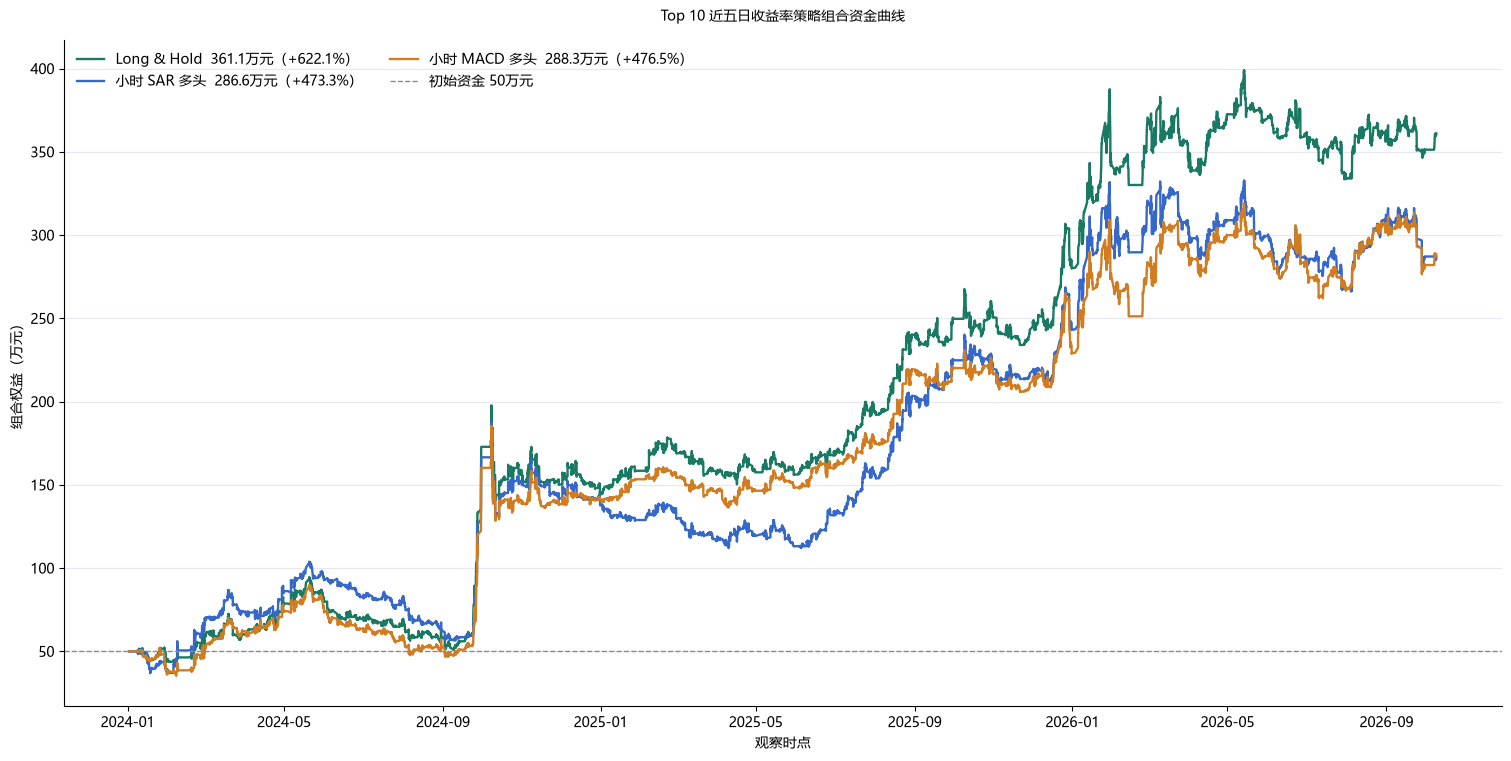

In [9]:
import csv as _csv
from datetime import datetime as _datetime
import matplotlib.dates as _mdates
import matplotlib.pyplot as _plt
from matplotlib.font_manager import FontProperties as _FontProperties
from matplotlib.ticker import FuncFormatter as _FuncFormatter

_equity_specs = [
    ("long_hold", "Long & Hold", "#187a63"),
    ("sar_long", "小时 SAR 多头", "#3568c8"),
    ("macd_long", "小时 MACD 多头", "#d17c20"),
]
_output_dir = BASE_DIR / "backtest_output"
_output_dir.mkdir(parents=True, exist_ok=True)
_font = _FontProperties(fname=r"C:\Windows\Fonts\msyh.ttc")
_fig, _ax = _plt.subplots(figsize=(15, 7.5), constrained_layout=True)
for _strategy_id, _label, _color in _equity_specs:
    _csv_path = _output_dir / f"equity_curve_{_strategy_id}.csv"
    if not _csv_path.exists():
        raise FileNotFoundError(f"请先运行回测导出单元，缺少文件：{_csv_path}")
    with _csv_path.open("r", encoding="utf-8-sig", newline="") as _file:
        _rows = list(_csv.DictReader(_file))
    if not _rows:
        raise ValueError(f"权益曲线文件为空：{_csv_path}")
    _times = [_datetime.fromisoformat(_row["timestamp"]) for _row in _rows]
    _equity = [float(_row["equity"]) for _row in _rows]
    _return = (_equity[-1] / INITIAL_CAPITAL - 1) * 100
    _ax.plot(_times, _equity, color=_color, linewidth=1.7,
             label=f"{_label}  {_equity[-1] / 10000:,.1f}万元（{_return:+.1f}%）")

_ax.axhline(INITIAL_CAPITAL, color="#858c98", linewidth=1, linestyle="--", label="初始资金 50万元")
_ax.set_title("Top 10 近五日收益率策略组合资金曲线", fontsize=16, pad=14, fontproperties=_font)
_ax.set_xlabel("观察时点", fontproperties=_font)
_ax.set_ylabel("组合权益（万元）", fontproperties=_font)
_ax.yaxis.set_major_formatter(_FuncFormatter(lambda _value, _position: f"{_value / 10000:,.0f}"))
_ax.xaxis.set_major_locator(_mdates.AutoDateLocator(minticks=6, maxticks=10))
_ax.xaxis.set_major_formatter(_mdates.DateFormatter("%Y-%m"))
_ax.grid(axis="y", color="#e5e9ef", linewidth=0.8)
_ax.spines[["top", "right"]].set_visible(False)
_ax.legend(loc="best", frameon=False, ncol=2, prop=_font)
for _tick_label in (*_ax.get_xticklabels(), *_ax.get_yticklabels()):
    _tick_label.set_fontproperties(_font)
_fig.savefig(_output_dir / "top10_portfolio_equity_curve.png", dpi=180, bbox_inches="tight")
_plt.show()


## 9. 持仓状态时间轴与指定时点持仓清单

时间轴按三套策略分别展示各品种实际持仓区间；横轴是回测时间，纵轴是品种，色条表示该品种在组合中持有。修改下方 `HOLDINGS_AT` 可以查询该时点（或此前最近一个观察点）实际持有的期货、合约代码、开仓价、标记价、浮动盈亏与排名。图由已导出的持仓快照生成，不需要重新运行回测。


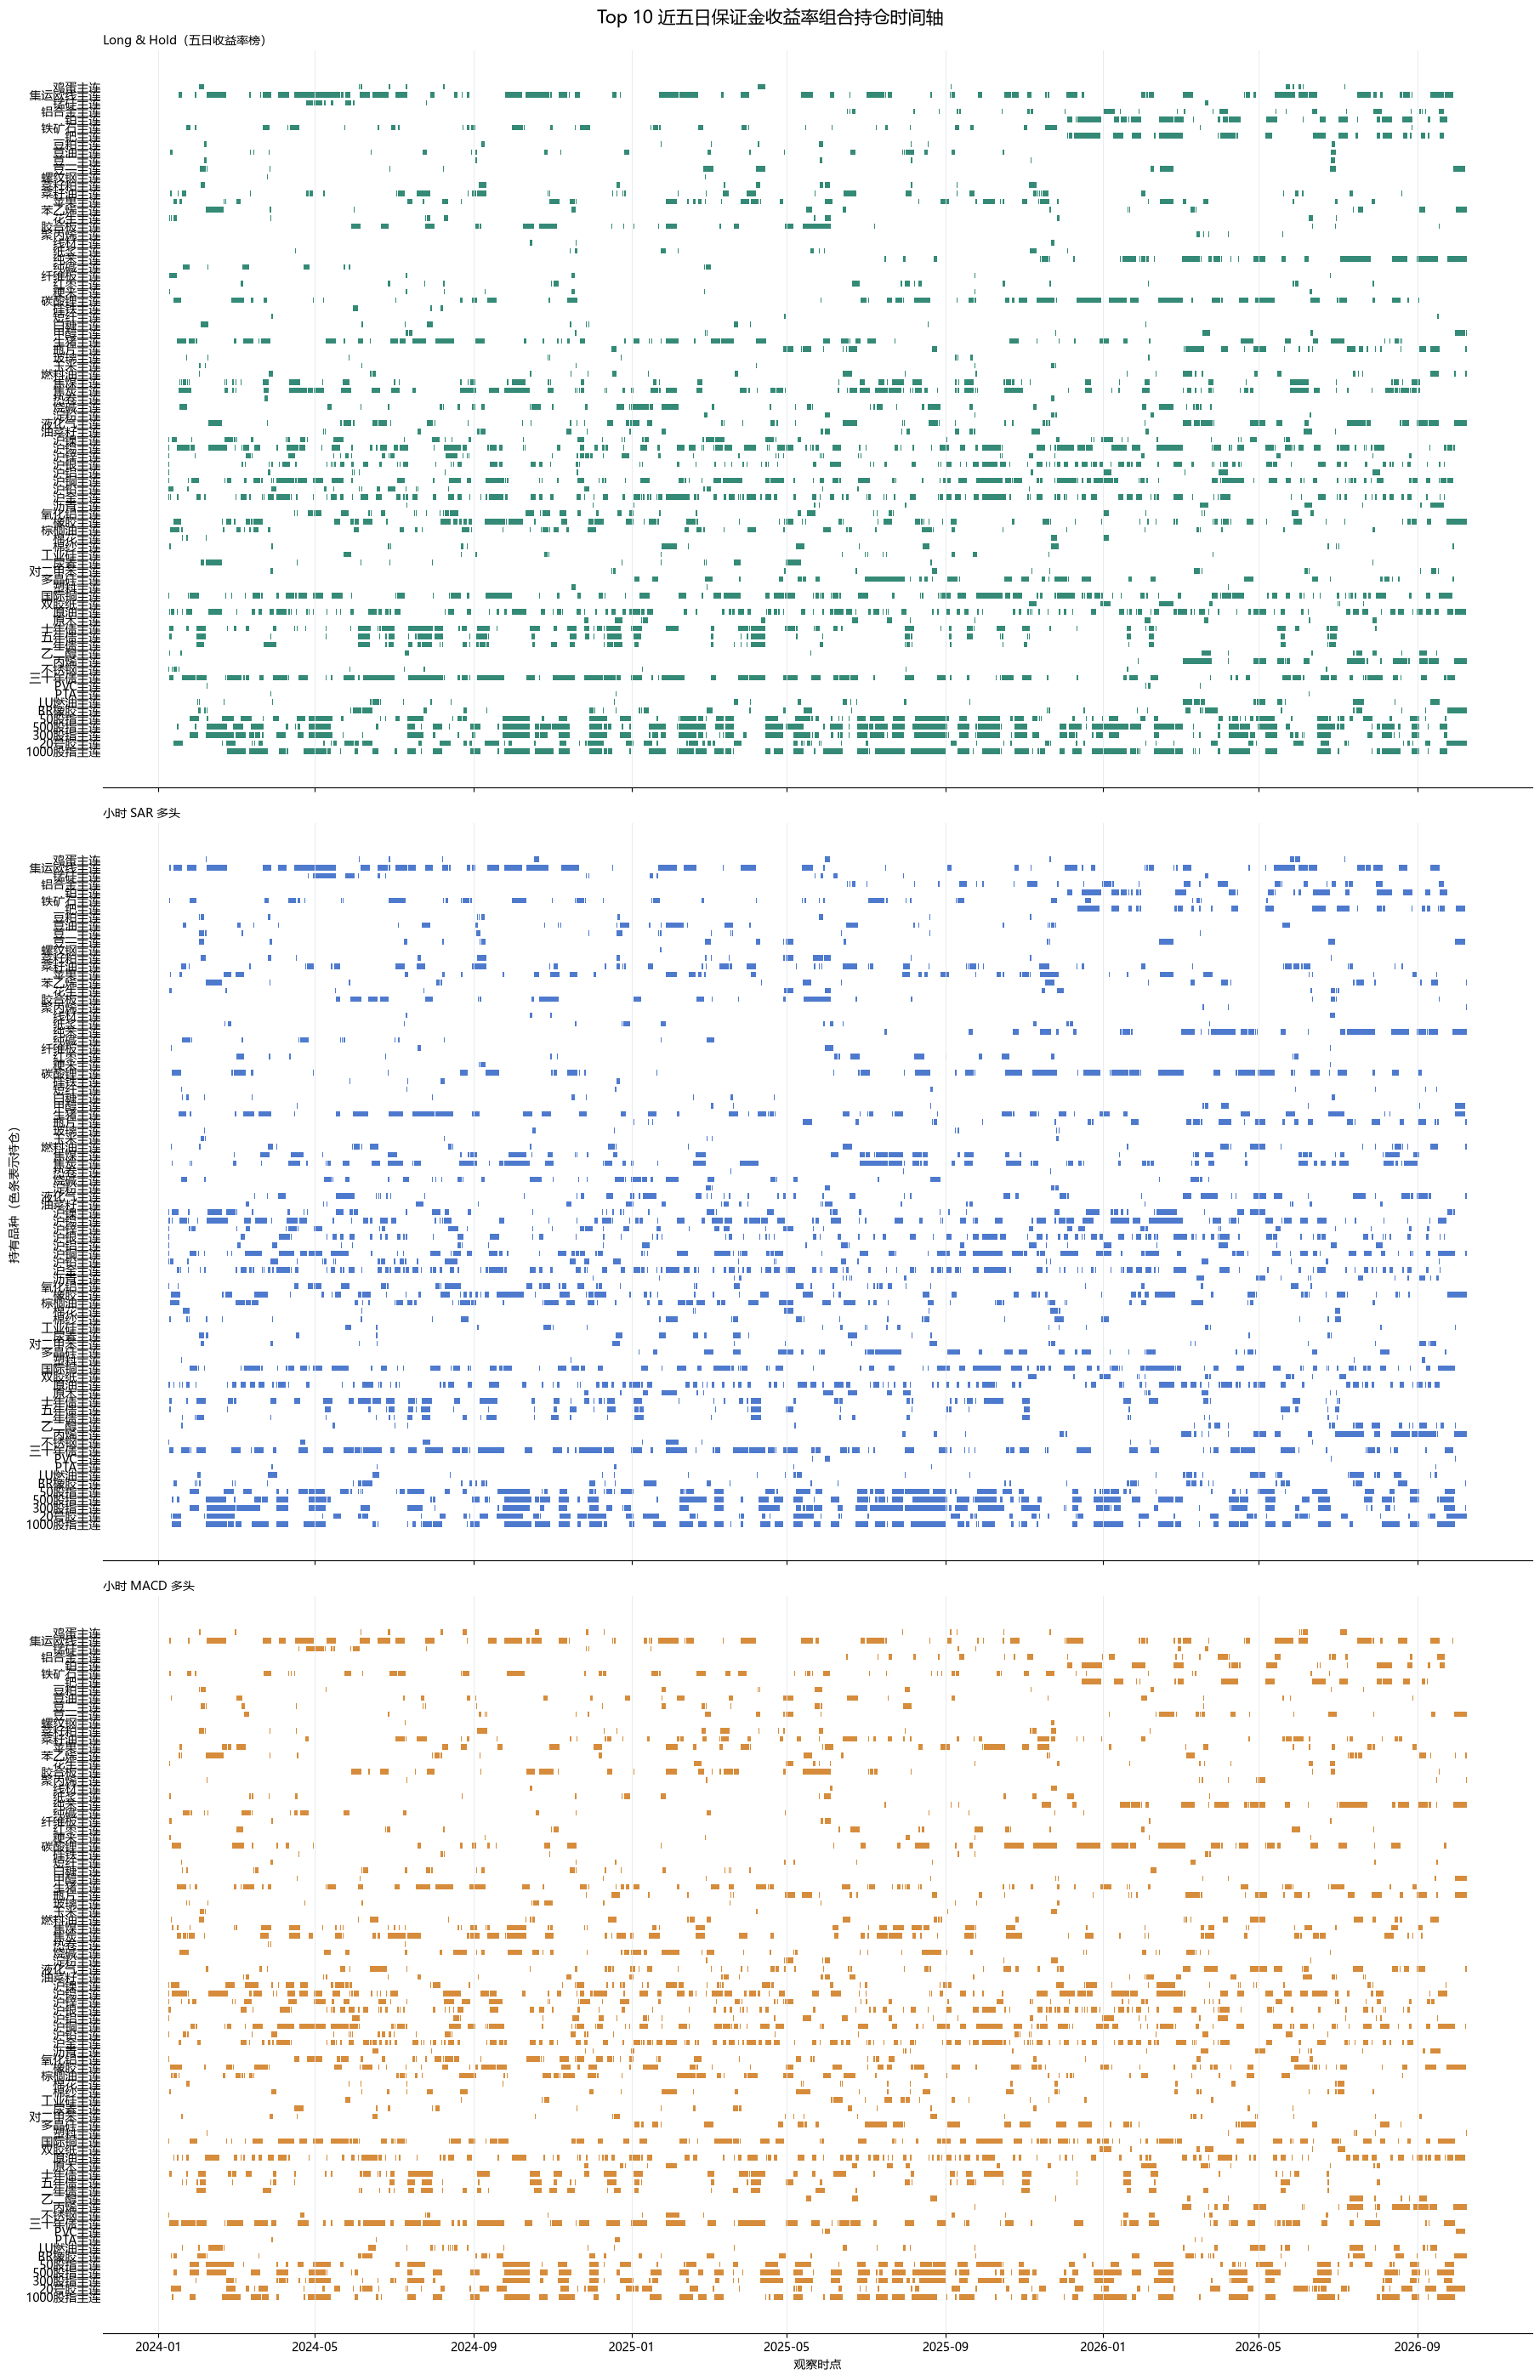

持仓时间轴已保存：d:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\backtest_output\top10_portfolio_holding_timeline.png
指定时点：2026-10-08 15:00:00；实际采用不晚于该时点的最近快照。


,策略,快照时点,品种,实际合约,开仓时点,开仓价,标记价,浮动盈亏,五日前一手保证金,五日净盈亏,五日排名,五日保证金收益率
0,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,20号胶主连,nr2611,2026-09-23 21:00:00,"16,745.00","17,410.00","6,650",—,—,10,1.27%
1,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,BR橡胶主连,br2611,2026-09-24 14:15:00,"15,680.00","16,590.00","4,550",—,—,7,1.38%
2,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,丙烯主连,PL2611,2026-09-29 10:00:00,"9,151.00","9,885.00","14,680",—,—,2,4.32%
3,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,原油主连,sc2611,2026-10-08 10:45:00,750.70,758.50,"7,800",—,—,6,1.86%
4,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,橡胶主连,ru2701,2026-09-29 21:00:00,"19,555.00","20,145.00","5,900",—,—,8,1.34%
5,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,液化气主连,pg2611,2026-09-30 11:15:00,"6,646.00","7,194.00","10,960",—,—,3,2.99%
6,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,燃料油主连,fu2611,2026-10-08 10:00:00,"5,094.00","5,179.00",850,—,—,5,2.02%
7,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,瓶片主连,PR2611,2026-10-08 10:00:00,"8,802.00","8,860.00",870,—,—,4,2.68%
8,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,纯苯主连,bz2611,2026-09-24 14:15:00,"9,097.00","9,449.00","30,600",—,—,1,4.82%
9,Long & Hold（五日收益率榜）,2026-10-08 15:00:00,苯乙烯主连,eb2611,2026-10-08 10:00:00,"10,668.00","10,692.00",120,—,—,9,1.30%


In [10]:
import csv as _csv
from datetime import datetime as _datetime
import matplotlib.dates as _mdates
import matplotlib.pyplot as _plt
from matplotlib.font_manager import FontProperties as _FontProperties
from matplotlib.ticker import MaxNLocator as _MaxNLocator
from IPython.display import display as _display
import pandas as _pd

# 可改成任意时点；若不是实际观察点，将展示该时点之前最近一次观察到的持仓。
HOLDINGS_AT = "2026-10-08 15:00:00"

_holding_specs = [
    ("long_hold", "Long & Hold（五日收益率榜）", "#187a63"),
    ("sar_long", "小时 SAR 多头", "#3568c8"),
    ("macd_long", "小时 MACD 多头", "#d17c20"),
]
_output_dir = BASE_DIR / "backtest_output"
_output_dir.mkdir(parents=True, exist_ok=True)
_font = _FontProperties(fname=r"C:\Windows\Fonts\msyh.ttc")

# 读取持仓快照并生成逐时点的实际持仓映射。
_holding_data = {}
_all_instruments = set()
for _strategy_id, _label, _color in _holding_specs:
    _path = _output_dir / f"positions_{_strategy_id}.csv"
    if not _path.exists():
        raise FileNotFoundError(f"请先运行回测导出单元，缺少持仓文件：{_path}")
    with _path.open("r", encoding="utf-8-sig", newline="") as _file:
        _rows = list(_csv.DictReader(_file))
    _times = sorted({_datetime.fromisoformat(_row["timestamp"]) for _row in _rows})
    _by_time = { _time: {} for _time in _times }
    for _row in _rows:
        _instrument = (_row.get("instrument") or "").strip()
        if not _instrument:
            continue
        _time = _datetime.fromisoformat(_row["timestamp"])
        _by_time[_time][_instrument] = _row
        _all_instruments.add(_instrument)
    _holding_data[_strategy_id] = (_label, _color, _times, _by_time)

# 三个面板共用同一品种纵轴，方便横向比较。
_instruments = sorted(_all_instruments)
_y = { _instrument: index for index, _instrument in enumerate(_instruments) }
_fig, _axes = _plt.subplots(3, 1, figsize=(18, max(27, len(_instruments) * 0.34)), sharex=True, sharey=True, constrained_layout=True)
for _ax, (_strategy_id, (_label, _color, _times, _by_time)) in zip(_axes, _holding_data.items()):
    _active_by_instrument = { _instrument: [] for _instrument in _instruments }
    for _time in _times:
        _active = _by_time[_time]
        for _instrument in _instruments:
            _active_by_instrument[_instrument].append(_instrument in _active)
    for _instrument, _states in _active_by_instrument.items():
        _index = 0
        while _index < len(_states):
            if not _states[_index]:
                _index += 1
                continue
            _start = _index
            while _index + 1 < len(_states) and _states[_index + 1]:
                _index += 1
            _end_time = _times[min(_index + 1, len(_times) - 1)]
            if _end_time == _times[_start] and len(_times) > 1:
                _end_time = _times[min(_start + 1, len(_times) - 1)]
            _left = _mdates.date2num(_times[_start])
            _width = max(_mdates.date2num(_end_time) - _left, 1 / 1440)
            _ax.broken_barh([(_left, _width)], (_y[_instrument] - 0.34, 0.68), facecolors=_color, alpha=0.88)
            _index += 1
    _ax.set_title(_label, loc="left", fontsize=11, fontproperties=_font, pad=5)
    _ax.grid(axis="x", color="#e5e9ef", linewidth=0.65)
    _ax.spines[["top", "right", "left"]].set_visible(False)
    _ax.set_yticks(range(len(_instruments)))
    _ax.set_yticklabels(_instruments, fontsize=5.2)
    _ax.tick_params(axis="y", length=0, labelsize=5.2, pad=2)
    for _tick in _ax.get_yticklabels():
        _tick.set_fontproperties(_font)
_axes[-1].xaxis.set_major_locator(_mdates.AutoDateLocator(minticks=6, maxticks=12))
_axes[-1].xaxis.set_major_formatter(_mdates.DateFormatter("%Y-%m"))
_axes[-1].set_xlabel("观察时点", fontproperties=_font)
_axes[1].set_ylabel("持有品种（色条表示持仓）", fontproperties=_font)
for _tick in _axes[-1].get_xticklabels():
    _tick.set_fontproperties(_font)
_fig.suptitle("Top 10 近五日保证金收益率组合持仓时间轴", fontsize=15, fontproperties=_font)
_timeline_path = _output_dir / "top10_portfolio_holding_timeline.png"
_fig.savefig(_timeline_path, dpi=170, bbox_inches="tight")
_plt.show()
print(f"持仓时间轴已保存：{_timeline_path}")

# 查询观察时点之前最近一条快照；不做前视填充。
_requested_time = _datetime.fromisoformat(HOLDINGS_AT)
_snapshot_rows = []
for _strategy_id, (_label, _color, _times, _by_time) in _holding_data.items():
    _eligible = [ _time for _time in _times if _time <= _requested_time ]
    if not _eligible:
        print(f"{_label}：所选时点早于数据起点，没有可用持仓快照。")
        continue
    _snapshot_time = _eligible[-1]
    for _instrument, _row in sorted(_by_time[_snapshot_time].items()):
        _snapshot_rows.append({
            "策略": _label,
            "快照时点": _snapshot_time.strftime("%Y-%m-%d %H:%M:%S"),
            "品种": _instrument,
            "实际合约": _row.get("contract", ""),
            "开仓时点": _row.get("entry_time", ""),
            "开仓价": float(_row["entry_price"]) if _row.get("entry_price") else None,
            "标记价": float(_row["mark_price"]) if _row.get("mark_price") else None,
            "浮动盈亏": float(_row["floating_pnl"]) if _row.get("floating_pnl") else 0.0,
            "五日前一手保证金": float(_row["five_day_margin"]) if _row.get("five_day_margin") else None,
            "五日净盈亏": float(_row["five_day_pnl"]) if _row.get("five_day_pnl") else None,
            "五日排名": int(float(_row["rank"])) if _row.get("rank") else None,
            "五日保证金收益率": float(_row["five_day_return"]) if _row.get("five_day_return") else None,
        })
_holdings_frame = _pd.DataFrame(_snapshot_rows)
if _holdings_frame.empty:
    print(f"{HOLDINGS_AT} 之前没有持仓数据。")
else:
    print(f"指定时点：{HOLDINGS_AT}；实际采用不晚于该时点的最近快照。")
    _display(_holdings_frame.style.format({
        "开仓价": "{:,.2f}", "标记价": "{:,.2f}", "浮动盈亏": "{:,.0f}", "五日前一手保证金": "{:,.0f}", "五日净盈亏": "{:,.0f}", "五日保证金收益率": "{:.2%}"
    }, na_rep="—"))
